# Exploratory Data Analysis and Regression Analysis. 

Exploratory Data Analysis and Regression Analysis on gross domestic product dataset

### I will examine the dataset in 12 stages.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")

# Display more columns
pd.set_option("display.max_columns", None)

# Display numbers to 3 decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

#### 2. Load the dataset

In [2]:
df = pd.read_csv(
    "gross-domestic-product-december-2025-quarter-visualisation.csv"
)

# Display the first five rows
print(df.head())

             Level                                        Description  \
0  Industry groups                                        Agriculture   
1  Industry groups                               Forestry and logging   
2  Industry groups  Fishing, aquaculture and agriculture, forestry...   
3  Industry groups                                             Mining   
4  Industry groups          Food, beverage, and tobacco manufacturing   

     SeriesRefSNDQ Quarter  Weight    Amount  
0  SG01RSC04B01AA1  1987Q2   0.050 1,596.686  
1  SG01RSC04B01AA2  1987Q2   0.004   120.463  
2  SG01RSC04B01AA3  1987Q2   0.007   201.055  
3  SG01RSC04B01BB1  1987Q2   0.014   530.698  
4  SG01RSC04B01CC1  1987Q2   0.056 1,145.595  


In [3]:
# To randomly inspect five observations:
print(df.sample(5, random_state=42))

                           Level                                  Description  \
5848  High level industry groups                                 Construction   
6839  High level industry groups             Financial and insurance services   
5060  High level industry groups         Arts, recreation, and other services   
1345             Industry groups                         Forestry and logging   
6816  High level industry groups  Electricity, gas, water, and waste services   

        SeriesRefSNDQ Quarter  Weight    Amount  
5848  SG01RSC02B01B03  2000Q2   0.043 1,892.427  
6839  SG01RSC02B01C05  2014Q4   0.056 3,154.792  
5060  SG01RSC02B01C11  1988Q3   0.026   781.352  
1345  SG01RSC04B01AA2  1997Q4   0.009   207.806  
6816  SG01RSC02B01B02  2014Q3   0.031 1,621.812  


#### 3. Understand the structure of the dataset
A. Number of rows and columns

In [4]:
print("Dataset shape:", df.shape)

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

Dataset shape: (8370, 6)
Number of rows: 8370
Number of columns: 6


In [5]:
# B. Column names
print(df.columns)

Index(['Level', 'Description', 'SeriesRefSNDQ', 'Quarter', 'Weight', 'Amount'], dtype='object')


In [6]:
# C. Data types
print(df.dtypes)

Level             object
Description       object
SeriesRefSNDQ     object
Quarter           object
Weight           float64
Amount           float64
dtype: object


In [7]:
# Notice that Quarter is currently an object (string). We will convert it into a proper quarterly time format later.

In [8]:
# D. Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8370 entries, 0 to 8369
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Level          8370 non-null   object 
 1   Description    8370 non-null   object 
 2   SeriesRefSNDQ  8370 non-null   object 
 3   Quarter        8370 non-null   object 
 4   Weight         8370 non-null   float64
 5   Amount         8370 non-null   float64
dtypes: float64(2), object(4)
memory usage: 392.5+ KB


#### 4. Check data quality

In [9]:
# Data cleaning is an important part of EDA. You should investigate missing values, duplicate records, and invalid values.
# A. Check missing values
missing_values = df.isnull().sum()
print(missing_values)

Level            0
Description      0
SeriesRefSNDQ    0
Quarter          0
Weight           0
Amount           0
dtype: int64


In [10]:
# Calculate missing-value percentages:
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

print(missing_percentage)

Level           0.000
Description     0.000
SeriesRefSNDQ   0.000
Quarter         0.000
Weight          0.000
Amount          0.000
dtype: float64


#### Visualize missing values:

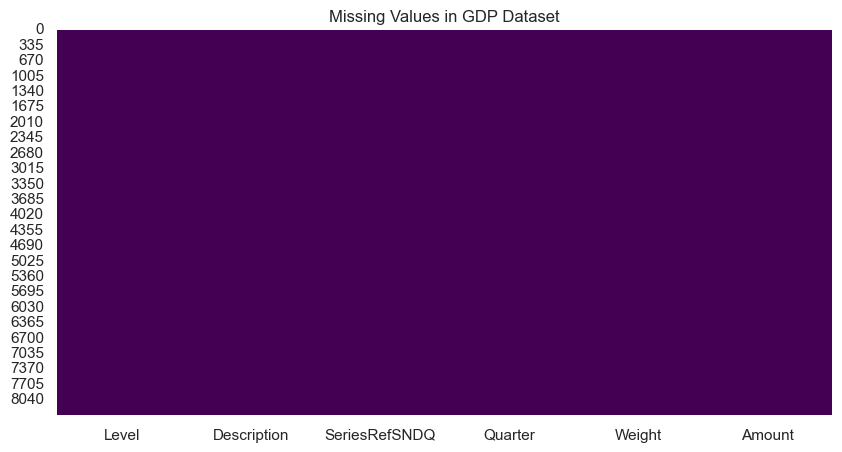

In [11]:

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in GDP Dataset")
plt.show()

In [12]:
# B. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
# To remove exact duplicates if necessary:
df = df.drop_duplicates()

In [14]:
# C. Check unique values
for column in df.columns:

    print(f"\nColumn: {column}")

    print("Unique values:", df[column].nunique())


Column: Level
Unique values: 4

Column: Description
Unique values: 43

Column: SeriesRefSNDQ
Unique values: 52

Column: Quarter
Unique values: 155

Column: Weight
Unique values: 1549

Column: Amount
Unique values: 6658


In [15]:
# This helps you understand the number of categories in each column.
# D. Check invalid numerical values
print("Negative Amount values:", (df["Amount"] < 0).sum())

print("Zero Amount values:", (df["Amount"] == 0).sum())

print("Negative Weight values:", (df["Weight"] < 0).sum())

Negative Amount values: 0
Zero Amount values: 0
Negative Weight values: 0


#### 5. Descriptive statistical analysis

In [16]:
# Descriptive statistics help you understand the distribution and characteristics of numerical data.
# A. Summary statistics
print(df.describe())

         Weight     Amount
count 8,370.000  8,370.000
mean      0.074  3,468.130
std       0.155  7,675.569
min       0.001     95.438
25%       0.019    806.024
50%       0.043  1,789.193
75%       0.063  3,014.430
max       1.000 70,996.972


In [17]:
# B. Statistical summary of categorical columns
print(df.describe(include="object"))
# This gives the count, number of unique values, most frequent value, and frequency of that value.

                  Level                               Description  \
count              8370                                      8370   
unique                4                                        43   
top     Industry groups  Rental, hiring, and real estate services   
freq               4960                                       310   

          SeriesRefSNDQ Quarter  
count              8370    8370  
unique               52     155  
top     SG01RSC04B01UZ9  1987Q2  
freq                465      54  


In [18]:
# C. Examine Amount separately
# Since Amount is our main variable of interest:
print("Mean:", df["Amount"].mean())

print("Median:", df["Amount"].median())

print("Mode:", df["Amount"].mode())

print("Standard deviation:", df["Amount"].std())

print("Variance:", df["Amount"].var())

print("Minimum:", df["Amount"].min())

print("Maximum:", df["Amount"].max())

print("Skewness:", df["Amount"].skew())

print("Kurtosis:", df["Amount"].kurt())

Mean: 3468.130433811231
Median: 1789.193
Mode: 0   1,436.139
Name: Amount, dtype: float64
Standard deviation: 7675.568784947267
Variance: 58914356.17245686
Minimum: 95.438
Maximum: 70996.972
Skewness: 5.552065092129454
Kurtosis: 34.02083716557344


Understanding skewness:
- Skewness near zero: approximately symmetrical distribution.
- Positive skewness: long tail towards higher values.
- Negative skewness: long tail towards lower values.
Your earlier analysis reported Amount skewness of approximately 5.55. This indicates a strongly right-skewed distribution.

Understanding kurtosis:

Kurtosis helps describe the heaviness of distribution tails. A high positive excess kurtosis suggests unusually heavy tails and potentially extreme observations.

#### 6. Univariate analysis: examine individual variables

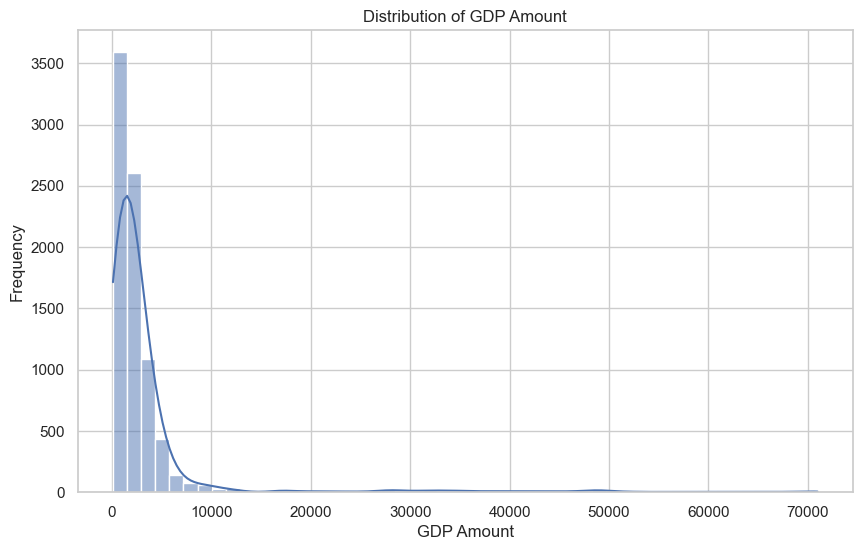

In [19]:
# Univariate analysis means examining one variable at a time.
# We will examine the numerical and categorical columns separately.
# A. Histogram of Amount
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount",
    bins=50,
    kde=True
)

plt.title("Distribution of GDP Amount")

plt.xlabel("GDP Amount")

plt.ylabel("Frequency")

plt.show()

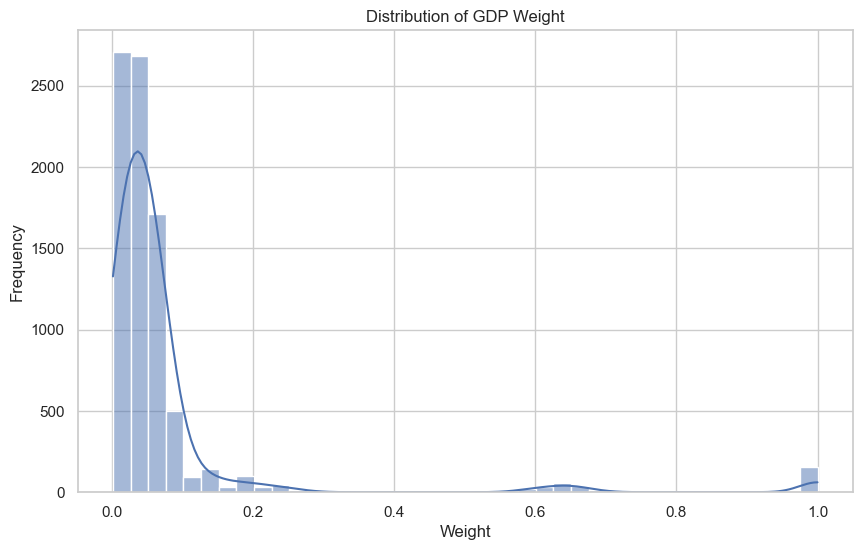

In [20]:
# B. Histogram of Weight
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Weight",
    bins=40,
    kde=True
)

plt.title("Distribution of GDP Weight")

plt.xlabel("Weight")

plt.ylabel("Frequency")

plt.show()

In [21]:
# C. Count the observations in each Level
print(df["Level"].value_counts())

Level
Industry groups               4960
High level industry groups    2635
Industry aggregates            620
Total GDP                      155
Name: count, dtype: int64


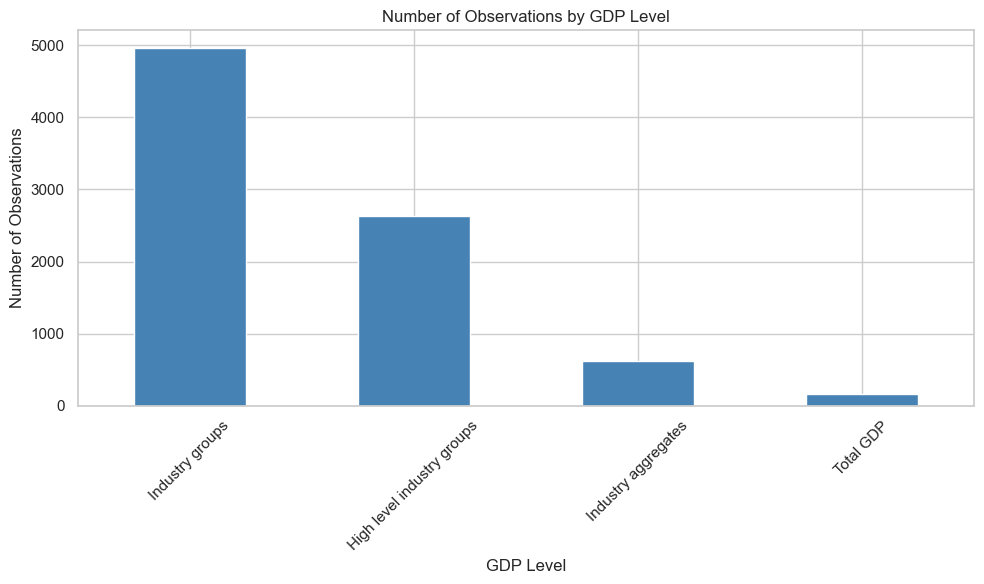

In [22]:
# Visualize the results:
plt.figure(figsize=(10, 6))

df["Level"].value_counts().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Number of Observations by GDP Level")

plt.xlabel("GDP Level")

plt.ylabel("Number of Observations")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [23]:
# D. Examine Description frequencies
description_counts = df["Description"].value_counts()

print(description_counts)

Description
Rental, hiring, and real estate services                                       310
Electricity, gas, water, and waste services                                    310
Education and training                                                         310
Mining                                                                         310
Health care and social assistance                                              310
Financial and insurance services                                               310
Information media and telecommunications                                       310
Transport, postal, and warehousing                                             310
GST, import duties, stamp duty                                                 310
Wholesale trade                                                                310
Construction                                                                   310
Arts and recreation services                                               

#### Visualize the 15 most frequent descriptions:


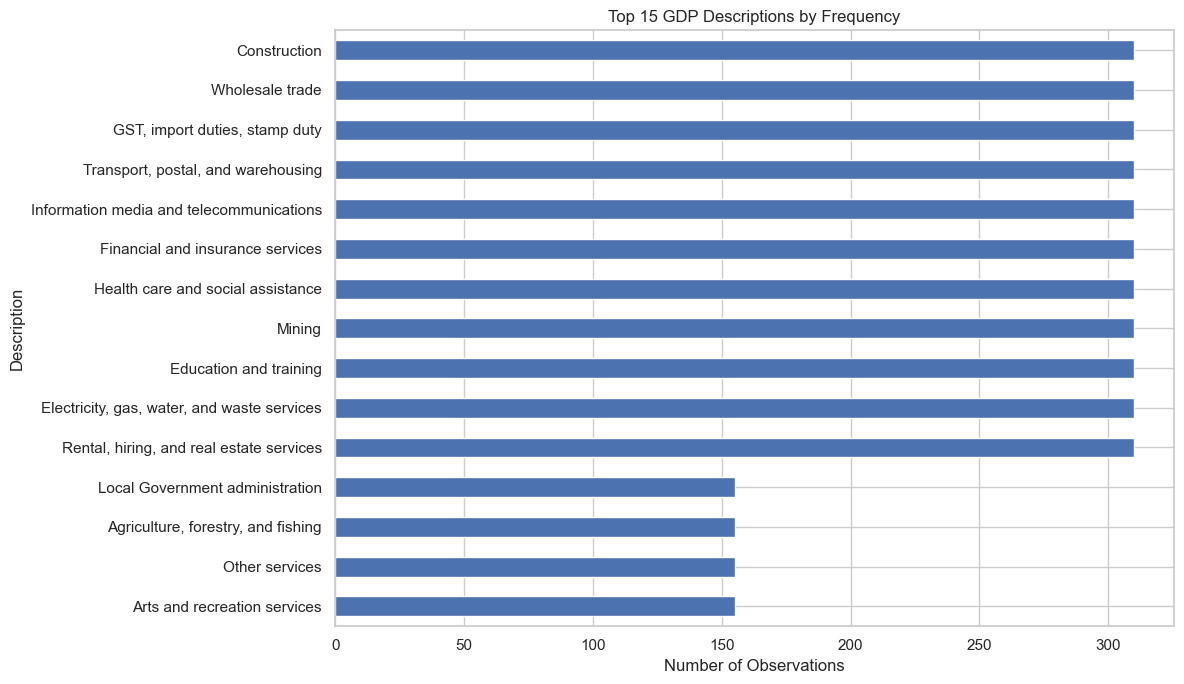

In [24]:
plt.figure(figsize=(12, 7))

description_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 GDP Descriptions by Frequency")

plt.xlabel("Number of Observations")

plt.ylabel("Description")

plt.tight_layout()

plt.show()

In [25]:
# E. Examine series reference frequencies
print(df["SeriesRefSNDQ"].value_counts().head(20))

SeriesRefSNDQ
SG01RSC04B01UZ9    465
SG01RSC04B01AA1    155
SG01RSC04B01AA2    155
SG01RSC04B01QQ1    155
SG01RSC04B01RS1    155
SG01RSC04B01RS2    155
SG01RSC02B01A01    155
SG01RSC02B01A02    155
SG01RSC02B01B01    155
SG01RSC02B01B02    155
SG01RSC02B01B03    155
SG01RSC02B01C01    155
SG01RSC02B01C02    155
SG01RSC02B01C03    155
SG01RSC02B01C04    155
SG01RSC02B01C05    155
SG01RSC02B01C06    155
SG01RSC02B01C07    155
SG01RSC02B01C08    155
SG01RSC02B01C09    155
Name: count, dtype: int64


#### 7. Bivariate analysis: examine relationships between variables

Bivariate analysis examines the relationship between two variables.
For the dataset, i am interested in the relationship between Weight and Amount, and how Amount differs across GDP classifications.

A. Relationship between Weight and Amount

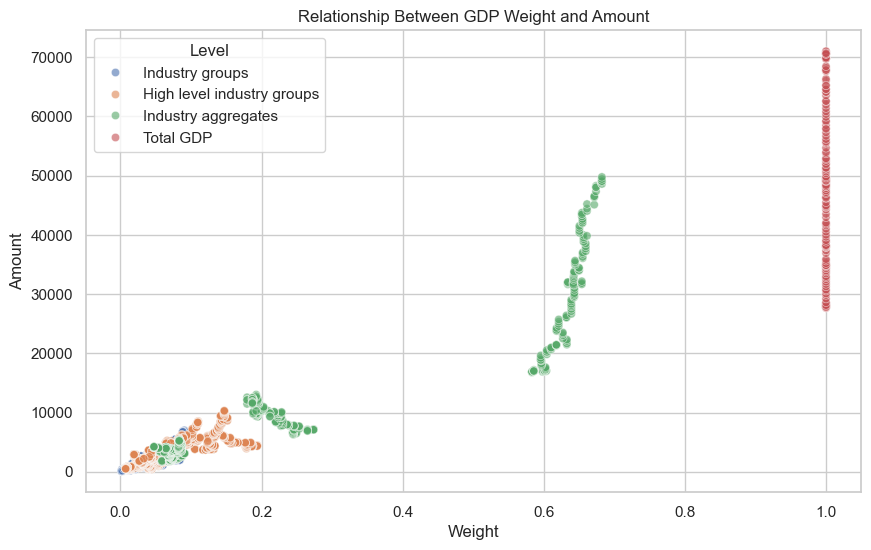

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Weight",
    y="Amount",
    hue="Level",
    alpha=0.6
)

plt.title("Relationship Between GDP Weight and Amount")

plt.xlabel("Weight")

plt.ylabel("Amount")

plt.show()

In [27]:
# B. Calculate correlation
correlation = df[["Weight", "Amount"]].corr()

print(correlation)

        Weight  Amount
Weight   1.000   0.948
Amount   0.948   1.000


#### Visualize the correlation:

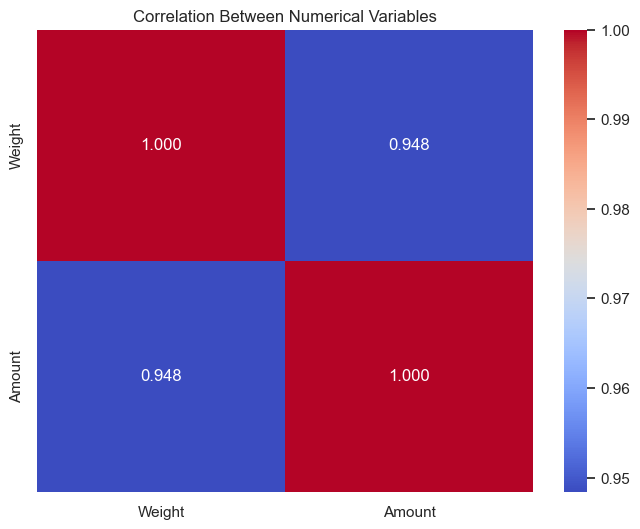

In [28]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".3f"
)

plt.title("Correlation Between Numerical Variables")

plt.show()

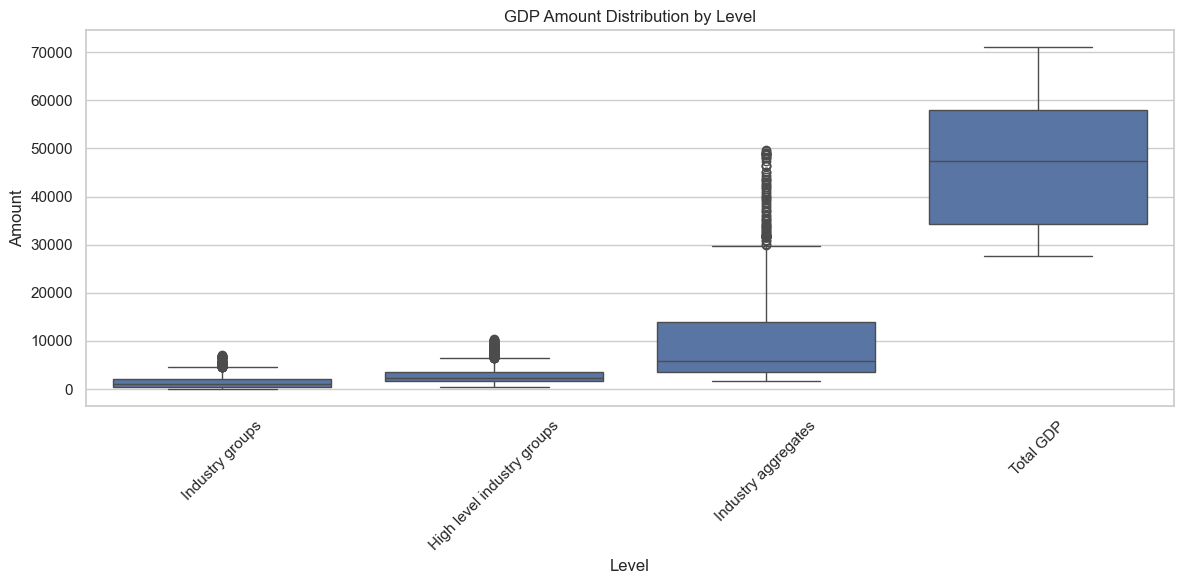

In [29]:
# C. Compare Amount across GDP levels
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Level",
    y="Amount"
)

plt.title("GDP Amount Distribution by Level")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

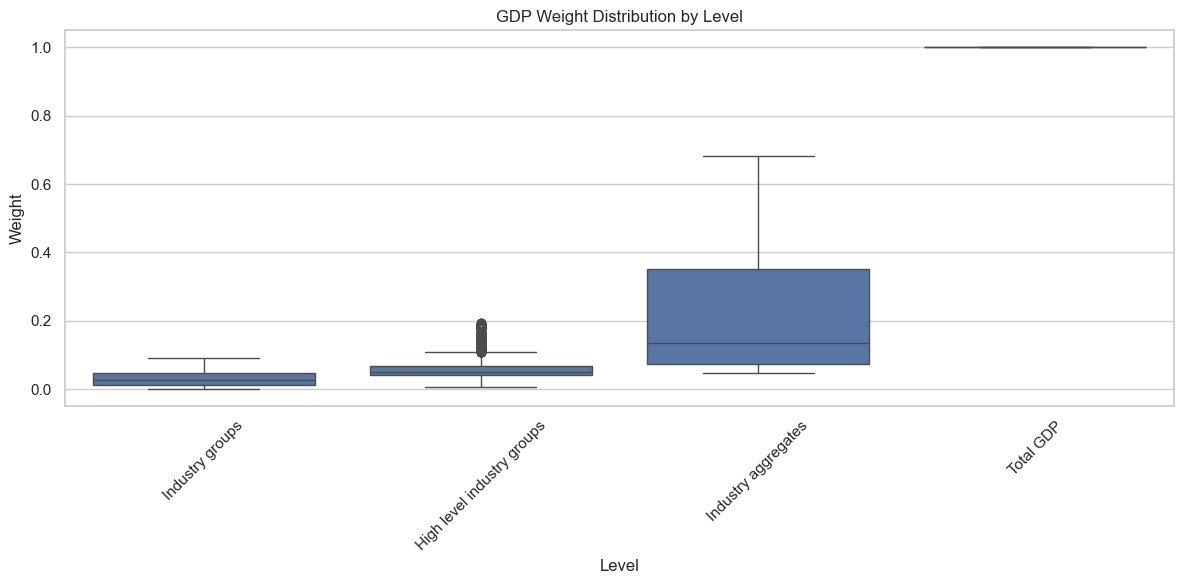

In [30]:
# D. Compare Weight across GDP levels
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Level",
    y="Weight"
)

plt.title("GDP Weight Distribution by Level")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [31]:
# E. Group-level statistical analysis
level_summary = df.groupby("Level")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(level_summary)

                            count       mean     median        std        min  \
Level                                                                           
High level industry groups   2635  2,758.420  2,328.437  1,714.867    433.118   
Industry aggregates           620 11,674.562  5,828.440 12,366.841  1,708.071   
Industry groups              4960  1,467.447  1,143.648  1,223.495     95.438   
Total GDP                     155 46,729.346 47,475.344 14,002.149 27,637.003   

                                  max  
Level                                  
High level industry groups 10,311.059  
Industry aggregates        49,763.440  
Industry groups             6,995.749  
Total GDP                  70,996.972  


In [32]:
# You can also compare descriptions:
description_summary = (
    df.groupby("Description")["Amount"]
      .agg(["count", "mean", "median", "std"])
      .sort_values("mean", ascending=False)
)

print(description_summary)

                                                    count       mean  \
Description                                                            
GDP                                                   155 46,729.346   
Services industries                                   155 30,515.572   
Goods producing industries                            155  9,431.280   
Manufacturing                                         155  5,307.045   
Prof, scientific, technical, admin, and support       155  4,666.420   
Rental, hiring, and real estate services              310  4,651.211   
Prof, scientific, and technical services              155  3,701.835   
Unallocated taxes                                     155  3,378.149   
GST, import duties, stamp duty                        310  3,378.149   
Primary industries                                    155  3,373.245   
Ownership of owner-occupied dwellings                 155  3,125.882   
Retail trade and accommodation                        155  3,048

##### 8. Outlier detection
An outlier is an observation that is unusually far from the majority of observations.

For your GDP dataset, outlier detection is particularly important because the Amount column has a strongly right-skewed distribution.

I will use the Interquartile Range (IQR) method.

In [33]:
Q1 = df["Amount"].quantile(0.25)

Q3 = df["Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Amount"] < lower_bound) |
    (df["Amount"] > upper_bound)
]

print("Lower boundary:", lower_bound)

print("Upper boundary:", upper_bound)

print("Number of outliers:", len(outliers))

print("Outlier percentage:",
      round(len(outliers) / len(df) * 100, 2), "%")

Lower boundary: -2506.584625
Upper boundary: 6327.038375
Number of outliers: 583
Outlier percentage: 6.97 %


#### Visualize outliers

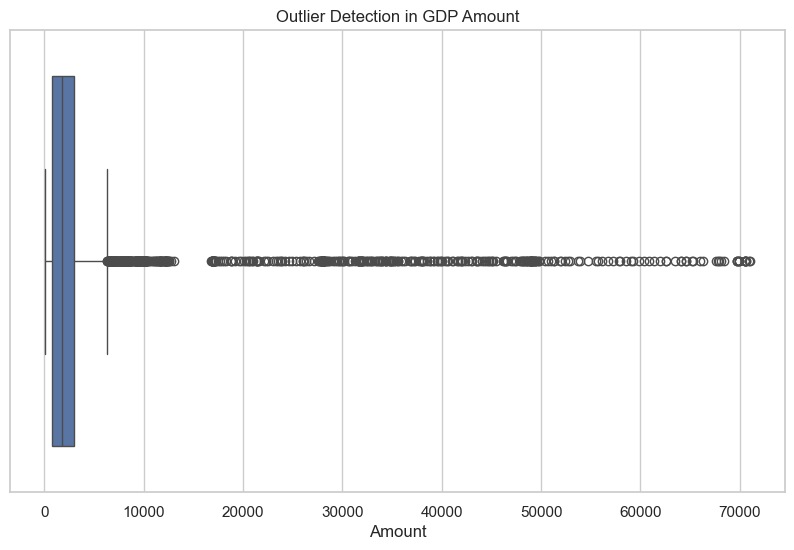

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=df["Amount"])

plt.title("Outlier Detection in GDP Amount")

plt.show()

A better approach to the above is to calculate outliers separately within each SeriesRefSNDQ:

In [35]:
def detect_outliers(group):

    q1 = group["Amount"].quantile(0.25)

    q3 = group["Amount"].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr

    upper = q3 + 1.5 * iqr

    return (
        (group["Amount"] < lower) |
        (group["Amount"] > upper)
    )


df["Amount_Outlier"] = (
    df.groupby("SeriesRefSNDQ", group_keys=False)
      .apply(detect_outliers)
)

print(df["Amount_Outlier"].value_counts())

Amount_Outlier
False    8340
True       30
Name: count, dtype: int64


##### 9. Time-series analysis: examine GDP over time
This is one of the most important sections of your EDA.

The Quarter column should be converted into a proper quarterly date format.
A. Convert Quarter into PeriodIndex

In [36]:
df["Quarter"] = pd.PeriodIndex(
    df["Quarter"].astype(str),
    freq="Q"
)

print(df[["Quarter", "Amount"]].head())

  Quarter    Amount
0  1987Q2 1,596.686
1  1987Q2   120.463
2  1987Q2   201.055
3  1987Q2   530.698
4  1987Q2 1,145.595


In [37]:
# B. Sort the dataset by quarter

In [38]:
df = df.sort_values(
    ["SeriesRefSNDQ", "Quarter"]
).reset_index(drop=True)

In [39]:
# C. Extract Total GDP
# Your dataset contains different GDP classifications. For an overall GDP trend, select the Total GDP category.

In [40]:
total_gdp = df[
    df["Level"] == "Total GDP"
].copy()

total_gdp = total_gdp.sort_values("Quarter")

print(total_gdp.head())

print(total_gdp.tail())

       Level Description SeriesRefSNDQ Quarter  Weight     Amount  \
0  Total GDP         GDP  SG01RSC00B01  1987Q2   1.000 27,977.446   
1  Total GDP         GDP  SG01RSC00B01  1987Q3   1.000 28,128.552   
2  Total GDP         GDP  SG01RSC00B01  1987Q4   1.000 28,258.771   
3  Total GDP         GDP  SG01RSC00B01  1988Q1   1.000 28,149.420   
4  Total GDP         GDP  SG01RSC00B01  1988Q2   1.000 28,019.240   

   Amount_Outlier  
0           False  
1           False  
2           False  
3           False  
4           False  
         Level Description SeriesRefSNDQ Quarter  Weight     Amount  \
150  Total GDP         GDP  SG01RSC00B01  2024Q4   1.000 69,728.468   
151  Total GDP         GDP  SG01RSC00B01  2025Q1   1.000 70,494.316   
152  Total GDP         GDP  SG01RSC00B01  2025Q2   1.000 69,885.643   
153  Total GDP         GDP  SG01RSC00B01  2025Q3   1.000 70,489.036   
154  Total GDP         GDP  SG01RSC00B01  2025Q4   1.000 70,663.589   

     Amount_Outlier  
150           Fa

In [41]:
# Check that you have one observation per quarter:

In [42]:
print("Total GDP rows:", len(total_gdp))

print("Unique quarters:", total_gdp["Quarter"].nunique())

print("Duplicate quarters:",
      total_gdp["Quarter"].duplicated().sum())

Total GDP rows: 155
Unique quarters: 155
Duplicate quarters: 0


In [43]:
# D. Plot Total GDP over time

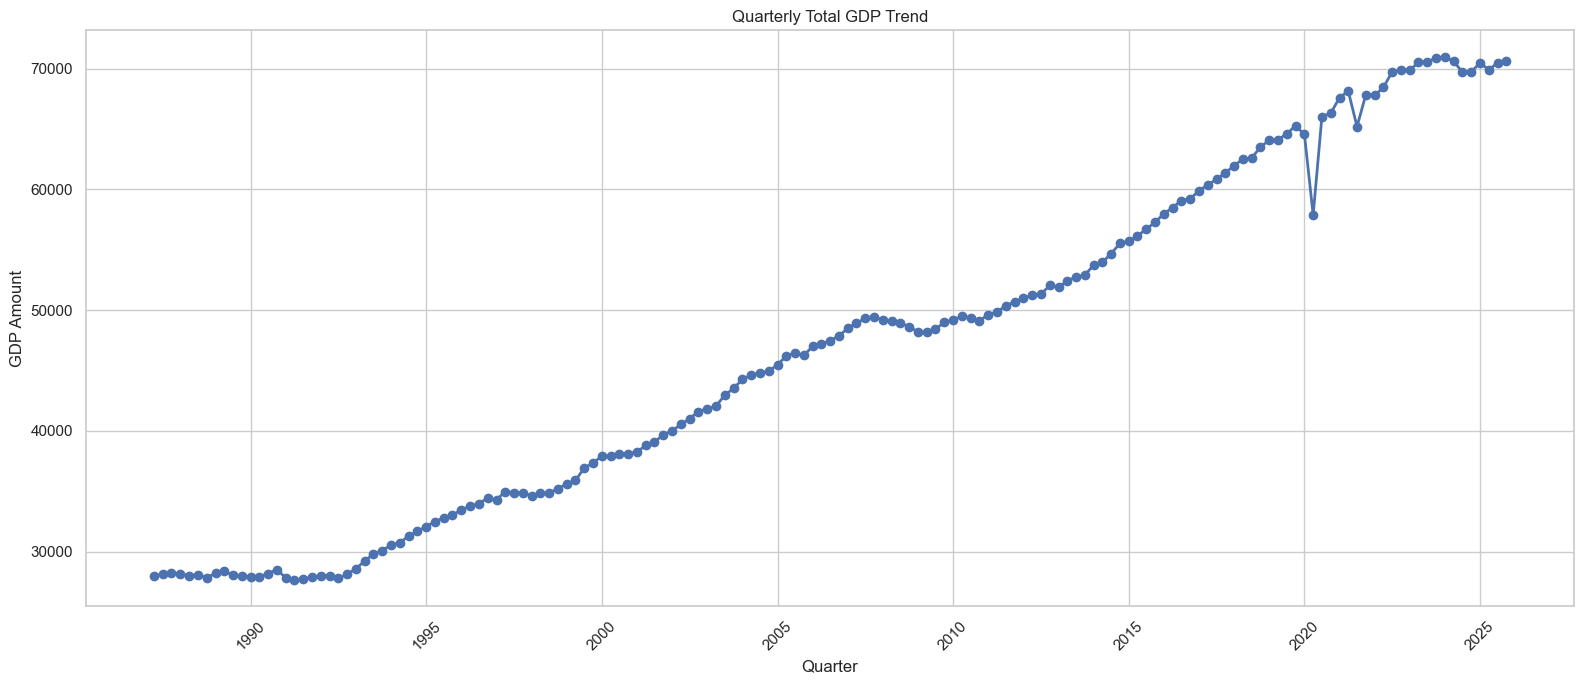

In [44]:
plt.figure(figsize=(16, 7))

plt.plot(
    total_gdp["Quarter"].dt.to_timestamp(),
    total_gdp["Amount"],
    marker="o",
    linewidth=2
)

plt.title("Quarterly Total GDP Trend")

plt.xlabel("Quarter")

plt.ylabel("GDP Amount")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

In [45]:
# E. Calculate quarterly GDP growth
# Quarter-on-quarter growth is calculated as:

In [46]:
total_gdp["QoQ_Growth"] = (
    total_gdp["Amount"].pct_change() * 100
)

print(
    total_gdp[
        ["Quarter", "Amount", "QoQ_Growth"]
    ].tail(10)
)

    Quarter     Amount  QoQ_Growth
145  2023Q3 70,563.645       0.062
146  2023Q4 70,881.680       0.451
147  2024Q1 70,996.972       0.163
148  2024Q2 70,596.388      -0.564
149  2024Q3 69,716.070      -1.247
150  2024Q4 69,728.468       0.018
151  2025Q1 70,494.316       1.098
152  2025Q2 69,885.643      -0.863
153  2025Q3 70,489.036       0.863
154  2025Q4 70,663.589       0.248


##### Visualize:

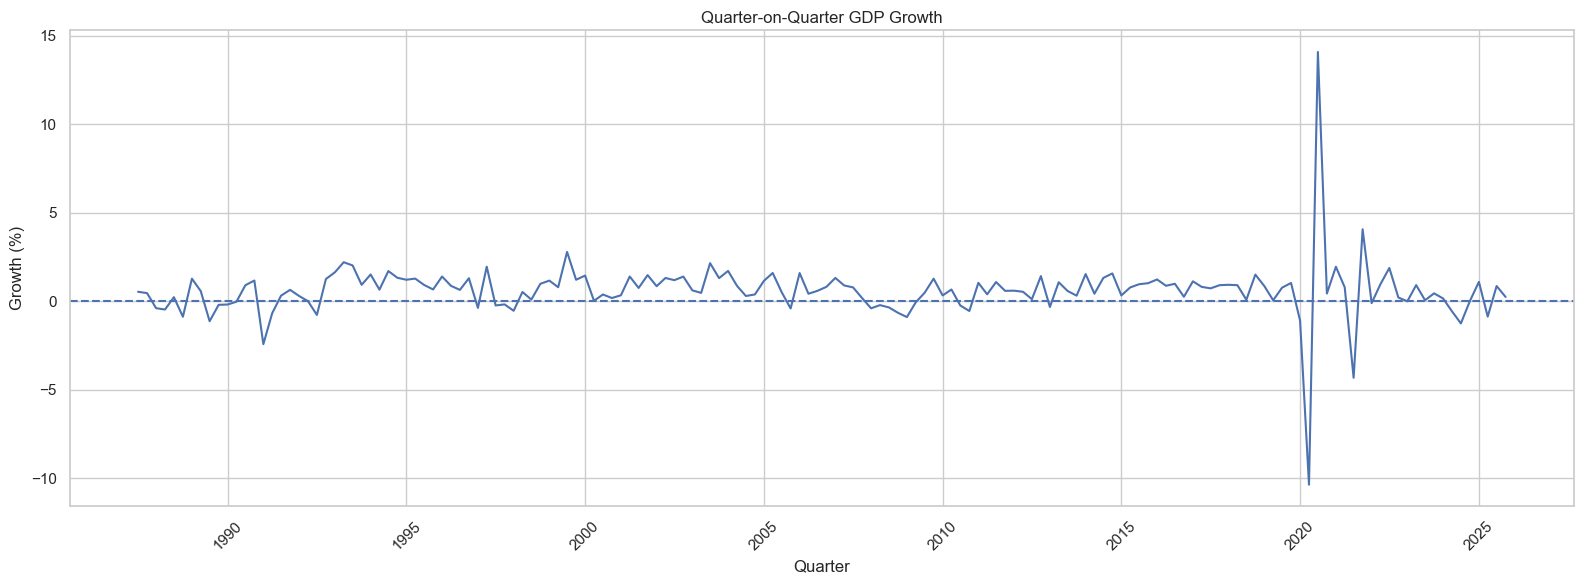

In [47]:
plt.figure(figsize=(16, 6))

plt.plot(
    total_gdp["Quarter"].dt.to_timestamp(),
    total_gdp["QoQ_Growth"]
)

plt.axhline(0, linestyle="--")

plt.title("Quarter-on-Quarter GDP Growth")

plt.xlabel("Quarter")

plt.ylabel("Growth (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [48]:
# F. Calculate year-on-year GDP growth
# For quarterly data,  i compared the current quarter with the same quarter one year earlier.

In [49]:
total_gdp["YoY_Growth"] = (
    total_gdp["Amount"].pct_change(4) * 100
)

print(
    total_gdp[
        ["Quarter", "Amount", "YoY_Growth"]
    ].tail(10)
)

    Quarter     Amount  YoY_Growth
145  2023Q3 70,563.645       1.198
146  2023Q4 70,881.680       1.435
147  2024Q1 70,996.972       1.598
148  2024Q2 70,596.388       0.108
149  2024Q3 69,716.070      -1.201
150  2024Q4 69,728.468      -1.627
151  2025Q1 70,494.316      -0.708
152  2025Q2 69,885.643      -1.007
153  2025Q3 70,489.036       1.109
154  2025Q4 70,663.589       1.341


##### Visualize:

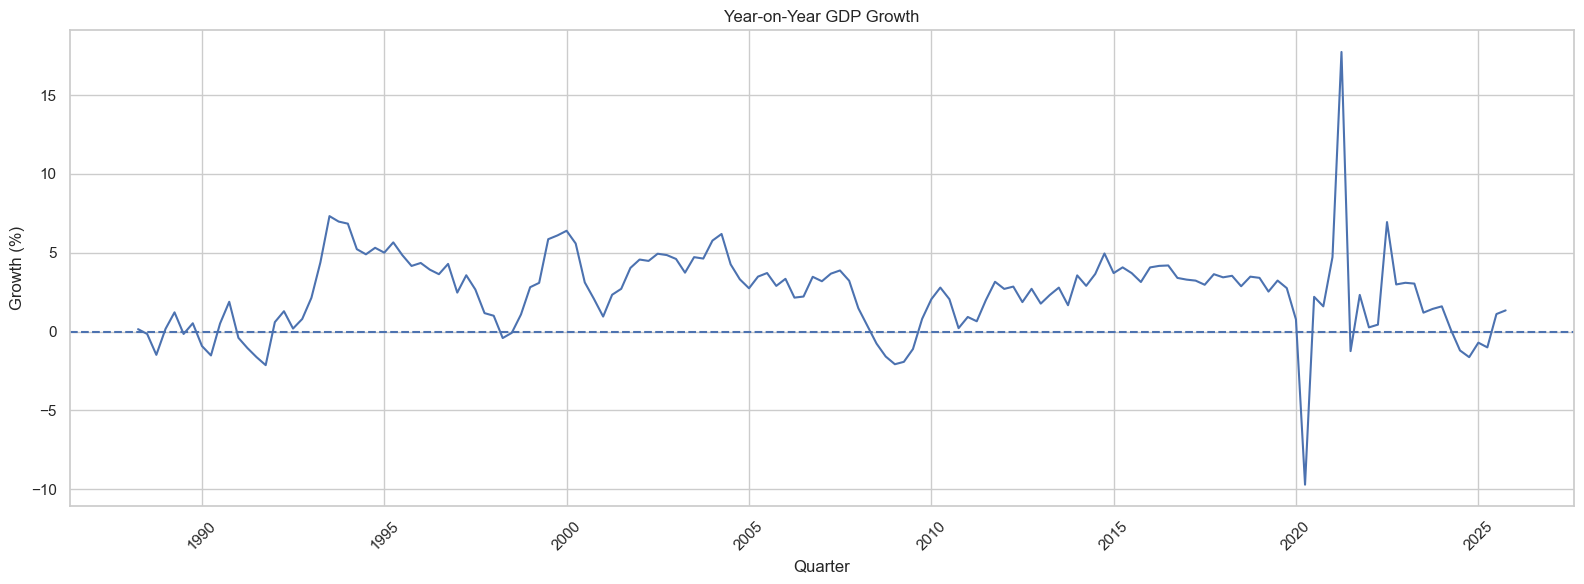

In [50]:
plt.figure(figsize=(16, 6))

plt.plot(
    total_gdp["Quarter"].dt.to_timestamp(),
    total_gdp["YoY_Growth"]
)

plt.axhline(0, linestyle="--")

plt.title("Year-on-Year GDP Growth")

plt.xlabel("Quarter")

plt.ylabel("Growth (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

#### 10. Trend and seasonality analysis
Trend describes the long-term direction of a time series, while seasonality describes recurring patterns at regular intervals.
    
A. Calculate moving averages

In [51]:
total_gdp["MA_4"] = (
    total_gdp["Amount"].rolling(window=4).mean()
)

total_gdp["MA_8"] = (
    total_gdp["Amount"].rolling(window=8).mean()
)

##### Visualize:

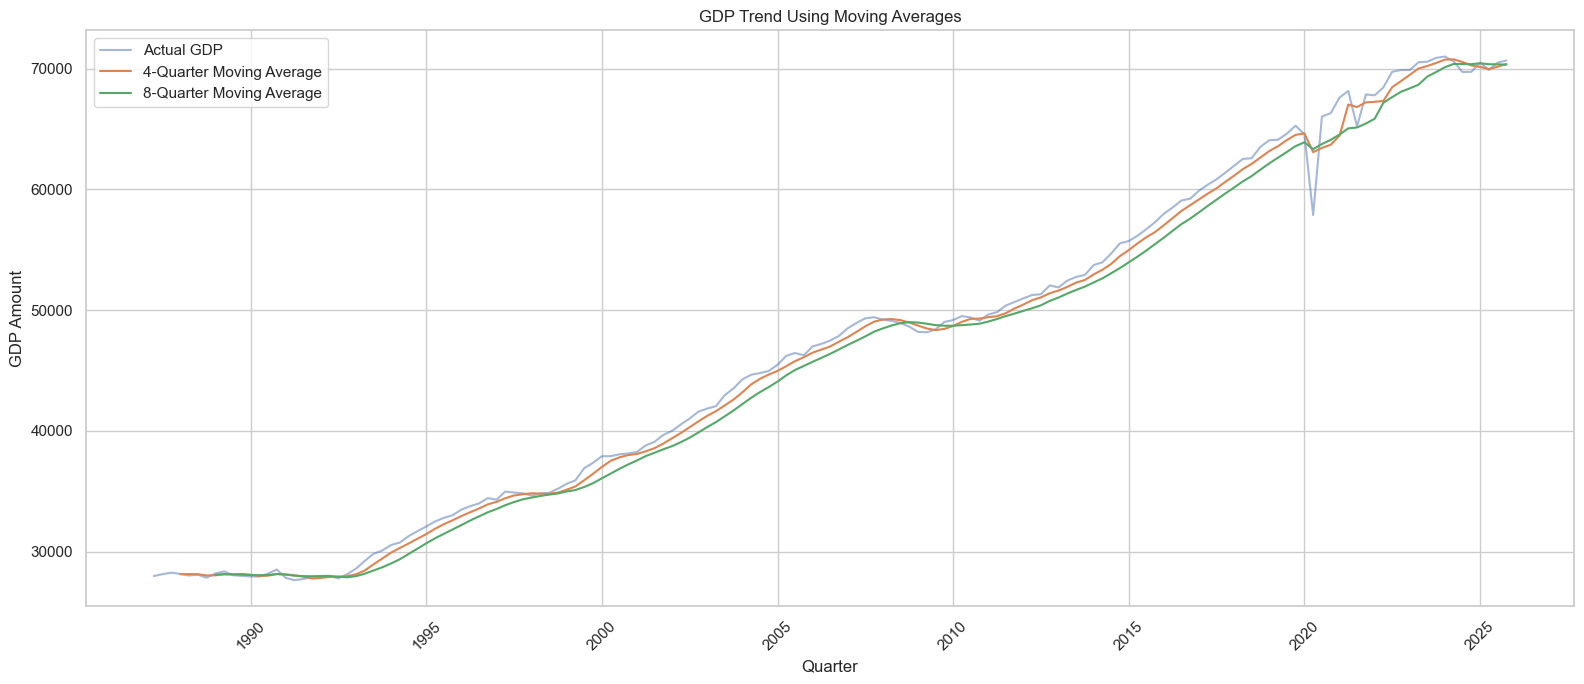

In [52]:
plt.figure(figsize=(16, 7))

plt.plot(
    total_gdp["Quarter"].dt.to_timestamp(),
    total_gdp["Amount"],
    label="Actual GDP",
    alpha=0.5
)

plt.plot(
    total_gdp["Quarter"].dt.to_timestamp(),
    total_gdp["MA_4"],
    label="4-Quarter Moving Average"
)

plt.plot(
    total_gdp["Quarter"].dt.to_timestamp(),
    total_gdp["MA_8"],
    label="8-Quarter Moving Average"
)

plt.title("GDP Trend Using Moving Averages")

plt.xlabel("Quarter")

plt.ylabel("GDP Amount")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

##### B. Seasonal decomposition
The GDP series can be decompose into:
1. Trend.
2. Seasonality.
3. Residuals.

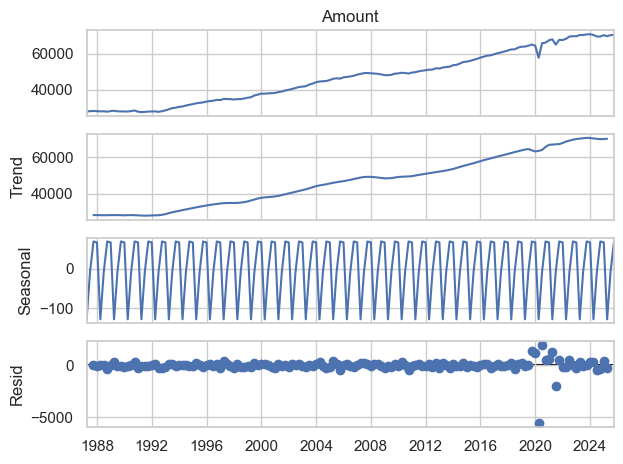

In [53]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Convert quarterly data into a time-indexed series
gdp_series = total_gdp.set_index(
    "Quarter"
)["Amount"]

gdp_series.index = gdp_series.index.to_timestamp()

# Seasonal decomposition
decomposition = seasonal_decompose(
    gdp_series,
    model="additive",
    period=4
)

decomposition.plot()

plt.tight_layout()

plt.show()

Important: Seasonal decomposition assumes the seasonal pattern is meaningful and reasonably stable.
11. Statistical analysis and hypothesis testing

For example, i can investigate whether the average GDP Amount differs across the four GDP levels.
A. Calculate Pearson correlation
I have already calculated the correlation between Weight and Amount. We can also test its statistical significance.

In [54]:
correlation, p_value = stats.pearsonr(
    df["Weight"],
    df["Amount"]
)

print("Pearson correlation:", correlation)

print("P-value:", p_value)

if p_value < 0.05:
    print("The correlation is statistically significant.")
else:
    print("The correlation is not statistically significant.")

Pearson correlation: 0.9484038922752388
P-value: 0.0
The correlation is statistically significant.


A small p-value suggests evidence of a linear association, but it does not establish causation.
B. Test whether GDP Amount differs across levels using ANOVA
ANOVA tests whether the means of three or more groups are equal.

The hypotheses are:
- Null hypothesis (H0): The mean GDP Amount is equal across all GDP levels.
- Alternative hypothesis (H1): At least one GDP level has a different mean.

In [55]:
groups = [
    group["Amount"].values
    for name, group in df.groupby("Level")
]

f_statistic, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_statistic)

print("P-value:", p_value)

if p_value < 0.05:
    print("There is evidence of a difference between GDP level means.")
else:
    print("There is insufficient evidence of a difference.")

F-statistic: 7030.283021685816
P-value: 0.0
There is evidence of a difference between GDP level means.


Important: ANOVA assumes independent observations and has distributional assumptions. My dataset contains repeated quarterly observations, so this basic ANOVA is exploratory rather than a complete time-series statistical test.


In [56]:
# C. Calculate descriptive statistics by GDP level
level_analysis = df.groupby("Level").agg(
    Total_Records=("Amount", "count"),
    Average_Amount=("Amount", "mean"),
    Median_Amount=("Amount", "median"),
    Standard_Deviation=("Amount", "std"),
    Minimum_Amount=("Amount", "min"),
    Maximum_Amount=("Amount", "max"),
    Average_Weight=("Weight", "mean")
)

print(level_analysis)

                            Total_Records  Average_Amount  Median_Amount  \
Level                                                                      
High level industry groups           2635       2,758.420      2,328.437   
Industry aggregates                   620      11,674.562      5,828.440   
Industry groups                      4960       1,467.447      1,143.648   
Total GDP                             155      46,729.346     47,475.344   

                            Standard_Deviation  Minimum_Amount  \
Level                                                            
High level industry groups           1,714.867         433.118   
Industry aggregates                 12,366.841       1,708.071   
Industry groups                      1,223.495          95.438   
Total GDP                           14,002.149      27,637.003   

                            Maximum_Amount  Average_Weight  
Level                                                       
High level industry grou

#### 12. Identify the highest and lowest GDP observations
This analysis helps you identify which observations have the largest and smallest GDP amounts.
    
A. Top 10 GDP observations

In [57]:
top_10 = df.nlargest(10, "Amount")[
    ["Level", "Description", "Quarter", "Weight", "Amount"]
]

print(top_10)

         Level Description Quarter  Weight     Amount
147  Total GDP         GDP  2024Q1   1.000 70,996.972
146  Total GDP         GDP  2023Q4   1.000 70,881.680
154  Total GDP         GDP  2025Q4   1.000 70,663.589
148  Total GDP         GDP  2024Q2   1.000 70,596.388
145  Total GDP         GDP  2023Q3   1.000 70,563.645
144  Total GDP         GDP  2023Q2   1.000 70,520.258
151  Total GDP         GDP  2025Q1   1.000 70,494.316
153  Total GDP         GDP  2025Q3   1.000 70,489.036
152  Total GDP         GDP  2025Q2   1.000 69,885.643
143  Total GDP         GDP  2023Q1   1.000 69,880.083


In [58]:
# B. Bottom 10 GDP observations

In [59]:
bottom_10 = df.nsmallest(10, "Amount")[
    ["Level", "Description", "Quarter", "Weight", "Amount"]
]

print(bottom_10)

                Level                                        Description  \
4007  Industry groups  Textile, leather, clothing, and footwear manuf...   
4317  Industry groups                                           Printing   
3255  Industry groups                               Forestry and logging   
4322  Industry groups                                           Printing   
4339  Industry groups                                           Printing   
4338  Industry groups                                           Printing   
4337  Industry groups                                           Printing   
4006  Industry groups  Textile, leather, clothing, and footwear manuf...   
4318  Industry groups                                           Printing   
4336  Industry groups                                           Printing   

     Quarter  Weight  Amount  
4007  2020Q2   0.002  95.438  
4317  2020Q2   0.002 105.422  
3255  1987Q2   0.004 120.463  
4322  2021Q3   0.002 123.003  
4339  20

In [60]:
# C. Highest and lowest Total GDP quarters

In [61]:
highest_gdp = total_gdp.loc[
    total_gdp["Amount"].idxmax()
]

lowest_gdp = total_gdp.loc[
    total_gdp["Amount"].idxmin()
]

print("Highest GDP:")
print(highest_gdp[["Quarter", "Amount"]])

print("\nLowest GDP:")
print(lowest_gdp[["Quarter", "Amount"]])

Highest GDP:
Quarter       2024Q1
Amount    70,996.972
Name: 147, dtype: object

Lowest GDP:
Quarter       1991Q2
Amount    27,637.003
Name: 16, dtype: object


##### 13. Additional analysis: create a GDP analytical summary
A summary table that combines important information about your dataset.

In [62]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Total columns",
        "Missing values",
        "Duplicate records",
        "Unique GDP levels",
        "Unique descriptions",
        "Unique series references",
        "Unique quarters",
        "Average Amount",
        "Median Amount",
        "Minimum Amount",
        "Maximum Amount",
        "Amount skewness",
        "Amount kurtosis",
        "Weight-Amount correlation"
    ],

    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["Level"].nunique(),
        df["Description"].nunique(),
        df["SeriesRefSNDQ"].nunique(),
        df["Quarter"].nunique(),
        df["Amount"].mean(),
        df["Amount"].median(),
        df["Amount"].min(),
        df["Amount"].max(),
        df["Amount"].skew(),
        df["Amount"].kurt(),
        df[["Weight", "Amount"]].corr().iloc[0, 1]
    ]
})

print(eda_summary)

                       Metric      Value
0          Total observations  8,370.000
1               Total columns      7.000
2              Missing values      0.000
3           Duplicate records      0.000
4           Unique GDP levels      4.000
5         Unique descriptions     43.000
6    Unique series references     52.000
7             Unique quarters    155.000
8              Average Amount  3,468.130
9               Median Amount  1,789.193
10             Minimum Amount     95.438
11             Maximum Amount 70,996.972
12            Amount skewness      5.552
13            Amount kurtosis     34.021
14  Weight-Amount correlation      0.948


In [63]:
# Save the summary:
eda_summary.to_csv(
    "Amount_EDA_Summary.csv",
    index=False
)

In [64]:
# You can also export the cleaned dataset:
df.to_csv(
    "Amount_Cleaned_EDA.csv",
    index=False
)

# Regression Analysis

In [65]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [66]:
# ==================================================
# 1. LOAD THE DATASET
# ==================================================

file_path = (
    "gross-domestic-product-december-2025-quarter-visualisation.csv"
)

df = pd.read_csv(file_path)

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
# Check that the required columns exist
required_columns = [
    "Amount", "Weight", "Level", "Description"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

Dataset shape: (8370, 6)

Column names:
['Level', 'Description', 'SeriesRefSNDQ', 'Quarter', 'Weight', 'Amount']


In [67]:
# ==================================================
# 2. CLEAN THE DATA
# ==================================================

# Convert numerical columns to numeric values
df["Amount"] = pd.to_numeric(
    df["Amount"], errors="coerce"
)

df["Weight"] = pd.to_numeric(
    df["Weight"], errors="coerce"
)

# Rows without a target cannot be used for supervised training
df = df.dropna(subset=["Amount"]).copy()

# Treat blank category values as missing
for col in ["Level", "Description"]:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)
print("\nMissing values:")
print(df[required_columns].isna().sum())


Missing values:
Amount         0
Weight         0
Level          0
Description    0
dtype: int64


In [68]:
# ==================================================
# 3. SELECT FEATURES AND TARGET
# ==================================================

# Features used to predict Amount
X = df[["Weight", "Level", "Description"]].copy()

# Target to predict
y = df["Amount"].copy()

print("\nFeatures:", X.columns.tolist())
print("Target:", "Amount")



Features: ['Weight', 'Level', 'Description']
Target: Amount


In [69]:
# ==================================================
# 4. SPLIT INTO TRAINING AND TESTING DATA
# ==================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 6696
Testing rows: 1674


In [70]:
# ==================================================
# 5. PREPROCESS THE FEATURES
# ==================================================

numeric_features = ["Weight"]
categorical_features = ["Level", "Description"]

# Numerical preprocessing
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        RobustScaler()
    )
])
# Categorical preprocessing
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])
# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

## RANDOM FOREST REGRESSOR MODEL

In [71]:
# ==================================================
# 6. BUILD AND TRAIN THE MODEL
# ==================================================

model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "regressor",
        RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

model.fit(X_train, y_train)

print("\nModel training completed.")


Model training completed.


In [72]:
# ==================================================
# 7. MAKE TEST PREDICTIONS
# ==================================================

y_pred = model.predict(X_test)


In [73]:
# ==================================================
# 8. EVALUATE THE MODEL
# ==================================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE FOR RANDOMFORESTREGRESSOR")
print("=================")
print(f"MAE:  {mae:,.3f}")
print(f"RMSE: {rmse:,.3f}")
print(f"R²:   {r2:.4f}")


MODEL PERFORMANCE FOR RANDOMFORESTREGRESSOR
MAE:  329.012
RMSE: 1,986.472
R²:   0.9400


In [74]:
# ==================================================
# 9. COMPARE ACTUAL AND PREDICTED AMOUNTS
# ==================================================

results = pd.DataFrame({
    "Actual_Amount": y_test.to_numpy(),
    "Predicted_Amount": y_pred
})

results["Absolute_Error"] = (
    results["Actual_Amount"]
    - results["Predicted_Amount"]
).abs()

print("\nFirst 10 test predictions:")
print(results.head(10).round(3).to_string(index=False))


First 10 test predictions:
 Actual_Amount  Predicted_Amount  Absolute_Error
     1,892.427         1,828.964          63.463
     3,154.792         3,130.592          24.200
       781.352           783.569           2.217
       207.806           208.364           0.558
     1,621.812         1,615.895           5.917
     1,917.202         2,014.357          97.155
     1,928.770         1,964.277          35.507
       523.873           492.843          31.030
     3,355.915         3,456.240         100.325
     1,204.262         1,142.561          61.701


In [75]:
# ==================================================
# 10. PREDICT AMOUNT FOR A NEW EXAMPLE
# ==================================================

# Use an existing row's feature values as a runnable example.
# This demonstrates the prediction process without guessing
# category names that may not exist in the dataset.

new_example = X_test.iloc[[0]].copy()

predicted_amount = model.predict(new_example)[0]

print("\nEXAMPLE PREDICTION")
print("=================")
print("Input features:")
print(new_example.to_string(index=False))
print(
    f"\nPredicted Amount: {predicted_amount:,.3f}"
)
print(
    f"Actual Amount for comparison: "
    f"{y_test.iloc[0]:,.3f}"
)



EXAMPLE PREDICTION
Input features:
 Weight                      Level  Description
  0.043 High level industry groups Construction

Predicted Amount: 1,828.964
Actual Amount for comparison: 1,892.427


In [76]:
# ==================================================
# 11. OPTIONAL: SAVE TEST RESULTS
# ==================================================

results.to_csv(
    "amount_prediction_results_randon_forest.csv",
    index=False
)

print("\nTest results saved to amount_prediction_results_randon_forest.csv")



Test results saved to amount_prediction_results_randon_forest.csv


## LASSO MODEL

In [77]:
# ==================================================
# 12. BUILD AND TRAIN THE MODEL FOR LASSO
# ==================================================
from sklearn.linear_model import Lasso
alpha = 1.0 # You can adjust the alpha parameter
modellasso = Pipeline([
    ("preprocessor", preprocessor),
    (
        "regressor",
        Lasso(
            alpha=alpha
        )
    )
])

modellasso.fit(X_train, y_train)

print("\nModel training  for Lasso completed.")


Model training  for Lasso completed.


In [78]:
# ==================================================
# 13. MAKE TEST PREDICTIONS FOR LASSO
# ==================================================

y_predlasso = modellasso.predict(X_test)

In [79]:
# ==================================================
# 14. EVALUATE THE MODEL FOR LASSO
# ==================================================

mae = mean_absolute_error(y_test, y_predlasso)

rmse = np.sqrt(
    mean_squared_error(y_test, y_predlasso)
)

r2 = r2_score(y_test, y_predlasso)

print("\nMODEL PERFORMANCE FOR LASSO")
print("=================")
print(f"MAE:  {mae:,.3f}")
print(f"RMSE: {rmse:,.3f}")
print(f"R²:   {r2:.4f}")


MODEL PERFORMANCE FOR LASSO
MAE:  921.616
RMSE: 2,515.175
R²:   0.9038


In [80]:
# ==================================================
# 15. COMPARE ACTUAL AND PREDICTED AMOUNTS FOR LASSO
# ==================================================

resultslasso = pd.DataFrame({
    "Actual_Amount": y_test.to_numpy(),
    "Predicted_Amount": y_predlasso
})

resultslasso["Absolute_Error"] = (
    resultslasso["Actual_Amount"]
    - resultslasso["Predicted_Amount"]
).abs()

print("\nFirst 10 test predictions for Lasso:")
print(resultslasso.head(10).round(3).to_string(index=False))


First 10 test predictions for Lasso:
 Actual_Amount  Predicted_Amount  Absolute_Error
     1,892.427         2,091.104         198.677
     3,154.792         2,729.859         424.933
       781.352         1,190.038         408.686
       207.806           409.266         201.460
     1,621.812         1,508.910         112.902
     1,917.202         1,197.421         719.781
     1,928.770         2,074.354         145.584
       523.873           685.842         161.969
     3,355.915         3,218.249         137.666
     1,204.262           882.327         321.935


In [81]:
# 16. PREDICT AMOUNT FOR A NEW EXAMPLE FOR LASSO
# ==================================================

# Use an existing row's feature values as a runnable example.
# This demonstrates the prediction process without guessing
# category names that may not exist in the dataset.

new_example = X_test.iloc[[0]].copy()

predicted_amount = modellasso.predict(new_example)[0]

print("\nEXAMPLE PREDICTION")
print("=================")
print("Input features:")
print(new_example.to_string(index=False))
print(
    f"\nPredicted Amount: {predicted_amount:,.3f}"
)
print(
    f"Actual Amount for comparison: "
    f"{y_test.iloc[0]:,.3f}"
)



EXAMPLE PREDICTION
Input features:
 Weight                      Level  Description
  0.043 High level industry groups Construction

Predicted Amount: 2,091.104
Actual Amount for comparison: 1,892.427


In [82]:
# ==================================================
# 17. OPTIONAL: SAVE TEST RESULTS FOR LASSO
# ==================================================

resultslasso.to_csv(
    "amount_prediction_results_for_lasso.csv",
    index=False
)

print("\nTest results saved to amount_prediction_results_for_lasso.csv")


Test results saved to amount_prediction_results_for_lasso.csv


## LINEAR REGRESSION MODEL

In [83]:
# ==================================================
# 18. BUILD AND TRAIN THE MODEL FOR LINEARREGRESSION
# ==================================================
from sklearn.linear_model import LinearRegression
alpha = 1.0 # You can adjust the alpha parameter
modelLR = Pipeline([
    ("preprocessor", preprocessor),
    (
        "regressor",
        LinearRegression(
        )
    )
])

modelLR.fit(X_train, y_train)

print("\nModel training  for Linear Regression completed.")


Model training  for Linear Regression completed.


In [84]:
# ==================================================
# 19. MAKE TEST PREDICTIONS FOR LINEARREGRESSION
# ==================================================

y_predLR = modelLR.predict(X_test)

In [85]:
# ==================================================
# 20. EVALUATE THE MODEL FOR LINEARREGRESSION
# ==================================================

mae = mean_absolute_error(y_test, y_predLR)

rmse = np.sqrt(
    mean_squared_error(y_test, y_predLR)
)

r2 = r2_score(y_test, y_predLR)

print("\nMODEL PERFORMANCE FOR LINEAR REGRESSION")
print("=================")
print(f"MAE:  {mae:,.3f}")
print(f"RMSE: {rmse:,.3f}")
print(f"R²:   {r2:.4f}")


MODEL PERFORMANCE FOR LINEAR REGRESSION
MAE:  933.583
RMSE: 2,507.008
R²:   0.9045


In [86]:
# ==================================================
# 21. COMPARE ACTUAL AND PREDICTED AMOUNTS FOR LINEARREGRESSION
# ==================================================

resultsLR = pd.DataFrame({
    "Actual_Amount": y_test.to_numpy(),
    "Predicted_Amount": y_predLR
})

resultsLR["Absolute_Error"] = (
    resultsLR["Actual_Amount"]
    - resultsLR["Predicted_Amount"]
).abs()

print("\nFirst 10 test predictions for Lasso:")
print(resultsLR.head(10).round(3).to_string(index=False))


First 10 test predictions for Lasso:
 Actual_Amount  Predicted_Amount  Absolute_Error
     1,892.427         1,973.454          81.027
     3,154.792         2,769.943         384.849
       781.352         1,157.855         376.503
       207.806           419.659         211.853
     1,621.812         1,524.397          97.415
     1,917.202         1,145.024         772.178
     1,928.770         2,135.297         206.527
       523.873           664.076         140.203
     3,355.915         2,942.543         413.372
     1,204.262           925.783         278.479


In [87]:
# 22. PREDICT AMOUNT FOR A NEW EXAMPLE FOR LINEARREGRESSION
# ==================================================

# Use an existing row's feature values as a runnable example.
# This demonstrates the prediction process without guessing
# category names that may not exist in the dataset.

new_example = X_test.iloc[[0]].copy()

predicted_amount = modelLR.predict(new_example)[0]

print("\nEXAMPLE PREDICTION")
print("=================")
print("Input features:")
print(new_example.to_string(index=False))
print(
    f"\nPredicted Amount: {predicted_amount:,.3f}"
)
print(
    f"Actual Amount for comparison: "
    f"{y_test.iloc[0]:,.3f}"
)


EXAMPLE PREDICTION
Input features:
 Weight                      Level  Description
  0.043 High level industry groups Construction

Predicted Amount: 1,973.454
Actual Amount for comparison: 1,892.427


In [88]:
# ==================================================
# 23. OPTIONAL: SAVE TEST RESULTS FOR LINEARREGRESSION
# ==================================================

resultsLR.to_csv(
    "amount_prediction_results_for_LinearRegression.csv",
    index=False
)

print("\nTest results saved to amount_prediction_results_for_LinearRegression.csv")


Test results saved to amount_prediction_results_for_LinearRegression.csv


Based on the evaluated metrics, the Random Forest Regressor outperformed the linear baselines. It achieved the lowest
Root Mean Squared Error (RMSE: 1,986.472) and (R² Score: 0.94OO), making it the optimal model choice for predicting future Amount.
Lasso and Linear Regression also reported R² values of 0.9038 and 0.9045 respectively. Lasso had a slightly lower MAE than Linear
Regression, while Linear Regression had a slightly lower RMSE and slightly higher R² has shown.
    
The dataset is a quarterly panel containing several GDP classifications and series. Initial EDA found no missing values or
exact duplicates, but revealed large differences in scale between levels, a highly right-skewed Amount distribution, potential outliers and a strong positive association between Weight and Amount.

For the reported general regression experiment, Random Forest was the strongest model among Linear Regression,
Lasso and Random Forest. It is the leading candidate from that comparison, but it has not thereby been validated as a
future GDP forecasting model.
 
My next assignment is a dedicated forecasting experiment on one consistent series, such as Total GDP, with chronological
evaluation and rolling-origin backtesting. Compare Random Forest, ETS, SARIMA and simple baselines before selecting
a forecasting model.